# 06 · Evaluation: Figures and Final Summary
**Grounded Conversational Chart Accessibility** — Section 6 of 6

This notebook makes **no new measurements**. It only reads the results saved by Sections 1–4 and turns them into the report's figures and one summary table.

| figure | shows | source |
|---|---|---|
| 1 | Hallucination rate **before vs after** verification | Section 3 + human audit |
| 2 | Rate by **question type** | Section 3 |
| 3 | Rate by **chart type** | Section 3 |
| 4 | **Confusion matrices** of the classifier | Section 4 |
| 5 | **SHAP summary** | Section 4 |
| 6 | *(extension)* Chart **images**: vision model alone vs with the layer | Section 3b |

Every figure is saved to `outputs/figures/` as a PNG for the report, and the numbers behind it are saved to `outputs/tables/`, so each chart can also be read as a table.

It needs only pandas and matplotlib (no scikit-learn), so it runs on your laptop.

## 6.1 Setup

In [1]:
import sys, shutil
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.colors import LinearSegmentedColormap
from src import config

FIG, TAB = config.FIG_DIR, config.TABLE_OUT
config.make_dirs()

# ---- chart style: quiet axes, one ink colour for text, colour only for the data ----
INK, INK_2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#9a9893", "#fcfcfb", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "font.size": 10, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False})

# One fixed colour per model + answer style, used the same way in every figure
# (palette checked for colour-blind separation; two colours are light, so every
# chart has a legend and its numbers are saved as a table)
SERIES = [("llama3.2-3b", "short",    "Llama 3.2 3B · short",          "#2a78d6"),
          ("llama3.2-3b", "sentence", "Llama 3.2 3B · sentence",       "#eb6834"),
          ("gemini-flash", "short",    "Gemini Flash-Lite · short",    "#1baf7a"),
          ("gemini-flash", "sentence", "Gemini Flash-Lite · sentence", "#eda100")]
BLUES = LinearSegmentedColormap.from_list("blues", ["#eef4fc", "#9ec5f4", "#3987e5", "#104281"])

def save(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"saved outputs/figures/{name}")

def load(path, **kw):
    "Read a results file, or return None (with a note) if that section wasn't run."
    path = Path(path)
    if not path.exists():
        print(f"  (missing: {path.relative_to(config.ROOT)} - run the section that makes it)")
        return None
    return pd.read_csv(path, **kw)

v = pd.read_csv(config.OUTPUT_DIR / "verified.csv")
print(f"Loaded {len(v)} verified answers.")

Loaded 800 verified answers.


## 6.2 Figure 1: hallucination rate before vs after verification

**Before** = how often the raw LLM answer was wrong.

**After** = how often a wrong answer still reaches the user. Every flagged answer is replaced, so the only wrong answers left are ones the verifier **missed**. Those can only be measured by the human audit (Section 3.7). We show:
- the audit's estimate (missed answers ÷ audited passed answers, applied to each group's passed answers), and
- a whisker up to the **95% upper bound**. The audit is a sample, so "0 missed" does not prove zero; it shows the true rate is very likely below that bound.

The bound uses the exact binomial method; with 0 misses in *n* audited answers it is close to the "rule of three" (3 ÷ *n*).

Audit: 0 missed hallucinations in 60 passed answers -> miss rate 0.0% (95% upper bound 4.9%)


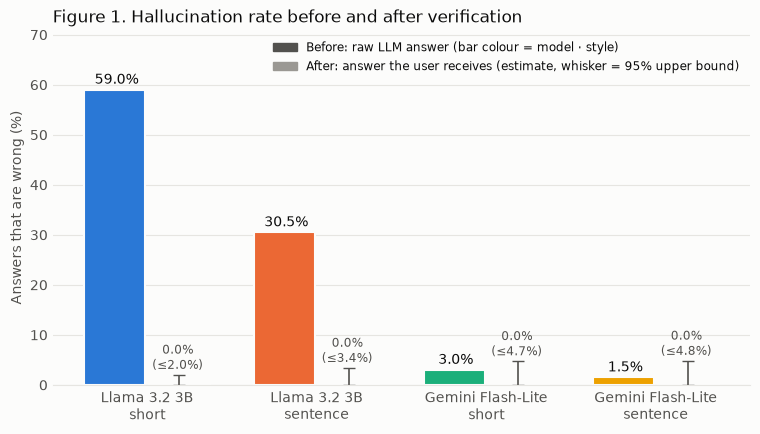

saved outputs/figures/fig1_before_after.png


,group,before_%,after_estimate_%,after_upper95_%,answers
0,Llama 3.2 3B · short,59.0,0.0,2.00,200
1,Llama 3.2 3B · sentence,30.5,0.0,3.38,200
2,Gemini Flash-Lite · short,3.0,0.0,4.72,200
3,Gemini Flash-Lite · sentence,1.5,0.0,4.80,200


In [2]:
def binom_upper(k, n, alpha=0.05):
    "One-sided exact upper bound for a proportion (k events in n trials)."
    from math import comb
    cdf = lambda p: sum(comb(n, i) * p**i * (1 - p)**(n - i) for i in range(k + 1))
    lo, hi = k / n, 1.0
    for _ in range(60):                          # bisection: find p where P(X <= k) = alpha
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if cdf(mid) > alpha else (lo, mid)
    return hi

audit = load(TAB / "audit_filled.csv")
if audit is not None:
    audit = audit[audit["human_label"].isin([0, 1, "0", "1"])]
    passed = ~v.loc[audit["row"], "hallucinated"].values           # verifier said "correct"
    truly_wrong = audit["human_label"].astype(int).values == 0
    n_pass, misses = int(passed.sum()), int((passed & truly_wrong).sum())
    miss_rate, miss_upper = misses / n_pass, binom_upper(misses, n_pass)
    print(f"Audit: {misses} missed hallucinations in {n_pass} passed answers "
          f"-> miss rate {100*miss_rate:.1f}% (95% upper bound {100*miss_upper:.1f}%)")
else:
    miss_rate = miss_upper = np.nan

rows = []
for model, style, label, colour in SERIES:
    g = v[(v.model == model) & (v["style"] == style)]
    before = g["hallucinated"].mean()
    rows.append({"group": label, "before_%": 100 * before,
                 "after_estimate_%": 100 * (1 - before) * miss_rate,
                 "after_upper95_%": 100 * (1 - before) * miss_upper, "answers": len(g)})
fig1 = pd.DataFrame(rows).round(2)
fig1.to_csv(TAB / "fig1_before_after.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.6))
x, w = np.arange(len(SERIES)), 0.36
for i, (model, style, label, colour) in enumerate(SERIES):
    r = fig1.iloc[i]
    ax.bar(x[i] - w/2 - 0.01, r["before_%"], w, color=colour, edgecolor=SURFACE, linewidth=1.5)
    ax.bar(x[i] + w/2 + 0.01, max(r["after_estimate_%"], 0.4), w, color=MUTED, edgecolor=SURFACE, linewidth=1.5)
    if not np.isnan(r["after_upper95_%"]):
        ax.errorbar(x[i] + w/2 + 0.01, r["after_estimate_%"], yerr=[[0], [r["after_upper95_%"] - r["after_estimate_%"]]],
                    fmt="none", ecolor=INK_2, elinewidth=1.2, capsize=4)
    ax.text(x[i] - w/2, r["before_%"] + 1.2, f"{r['before_%']:.1f}%", ha="center", fontsize=10, color=INK)
    ax.text(x[i] + w/2, (r["after_upper95_%"] if not np.isnan(r["after_upper95_%"]) else 0) + 1.2,
            f"{r['after_estimate_%']:.1f}%\n(≤{r['after_upper95_%']:.1f}%)", ha="center", fontsize=8.5, color=INK_2)
ax.set_xticks(x, [s[2].replace(" · ", "\n") for s in SERIES])
ax.set_ylabel("Answers that are wrong (%)")
ax.set_ylim(0, max(fig1["before_%"]) * 1.2)
ax.tick_params(length=0)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=INK_2, label="Before: raw LLM answer (bar colour = model · style)"),
                   Patch(color=MUTED, label="After: answer the user receives (estimate, whisker = 95% upper bound)")],
          loc="upper right", fontsize=8.5)
ax.set_title("Figure 1. Hallucination rate before and after verification")
save(fig, "fig1_before_after.png")
fig1

## 6.3 Figure 2: hallucination rate by question type

Raw (before-verification) rates, split by what the question asked. `n` = number of questions of that type, each answered by every model and style. **Types with small n (trend, sum, avg, compare) are uncertain**: one answer changes the rate by several points.

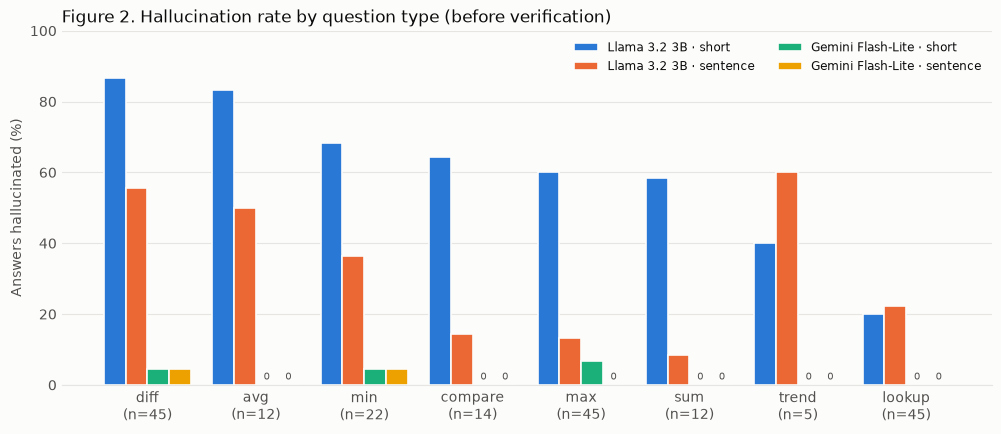

saved outputs/figures/fig2_by_question_type.png


,Llama 3.2 3B · short,Llama 3.2 3B · sentence,Gemini Flash-Lite · short,Gemini Flash-Lite · sentence,n_questions
qtype,,,,,
diff,86.7,55.6,4.4,4.4,45
avg,83.3,50.0,0.0,0.0,12
min,68.2,36.4,4.5,4.5,22
compare,64.3,14.3,0.0,0.0,14
max,60.0,13.3,6.7,0.0,45
sum,58.3,8.3,0.0,0.0,12
trend,40.0,60.0,0.0,0.0,5
lookup,20.0,22.2,0.0,0.0,45


In [3]:
def grouped_rates(by, title, fname, order=None):
    rate = v.pivot_table(index=by, columns=["model", "style"], values="hallucinated", aggfunc="mean") * 100
    n = v.groupby(by)["qid"].nunique()
    if order is None:                                    # sort by Llama-short rate, highest first
        order = rate[("llama3.2-3b", "short")].sort_values(ascending=False).index
    rate, n = rate.loc[order], n.loc[order]

    table = pd.DataFrame({s[2]: rate[(s[0], s[1])].round(1) for s in SERIES})
    table["n_questions"] = n
    table.to_csv(TAB / fname.replace(".png", ".csv"))

    fig, ax = plt.subplots(figsize=(max(8, 1.25 * len(order) + 2), 4.6))
    x, w = np.arange(len(order)), 0.2
    for i, (model, style, label, colour) in enumerate(SERIES):
        vals = rate[(model, style)].values
        ax.bar(x + (i - 1.5) * w, vals, w, label=label, color=colour, edgecolor=SURFACE, linewidth=1.2)
        for xi, val in zip(x + (i - 1.5) * w, vals):     # a 0% bar is invisible, so label it
            if val == 0:
                ax.text(xi, 0.8, "0", ha="center", va="bottom", fontsize=7.5, color=INK_2)
    ax.set_xticks(x, [f"{c}\n(n={n[c]})" for c in order])
    ax.set_ylabel("Answers hallucinated (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(length=0)
    ax.legend(ncol=2, fontsize=8.5, loc="upper right")
    ax.set_title(title)
    save(fig, fname)
    return table

grouped_rates("qtype", "Figure 2. Hallucination rate by question type (before verification)",
              "fig2_by_question_type.png")

## 6.4 Figure 3: hallucination rate by chart type

Same measure, split by chart type. Remember the chart type is **inferred from the table's shape** (Section 1). We saw in 3b that this heuristic sometimes calls a bar chart a "pie", so read this figure with that caveat.

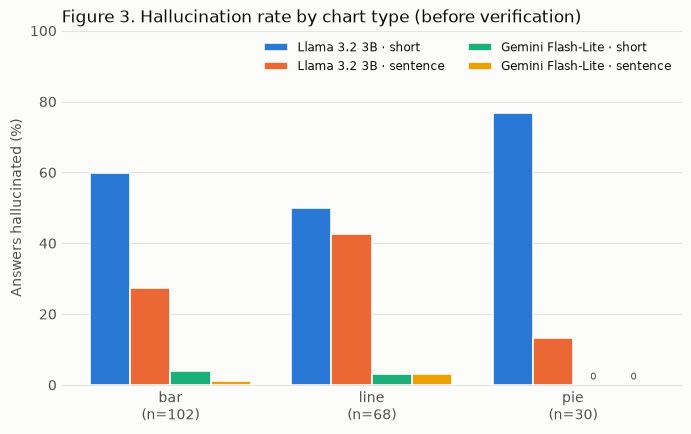

saved outputs/figures/fig3_by_chart_type.png


,Llama 3.2 3B · short,Llama 3.2 3B · sentence,Gemini Flash-Lite · short,Gemini Flash-Lite · sentence,n_questions
chart_type,,,,,
bar,59.8,27.5,3.9,1.0,102
line,50.0,42.6,2.9,2.9,68
pie,76.7,13.3,0.0,0.0,30


In [4]:
grouped_rates("chart_type", "Figure 3. Hallucination rate by chart type (before verification)",
              "fig3_by_chart_type.png", order=["bar", "line", "pie"])

## 6.5 Figure 4: confusion matrices of the classifier

From Section 4's held-out test answers; an answer is predicted "hallucinated" if its predicted risk is at least 0.5. The bottom-left cell (**missed hallucinations**) is the one to keep small.

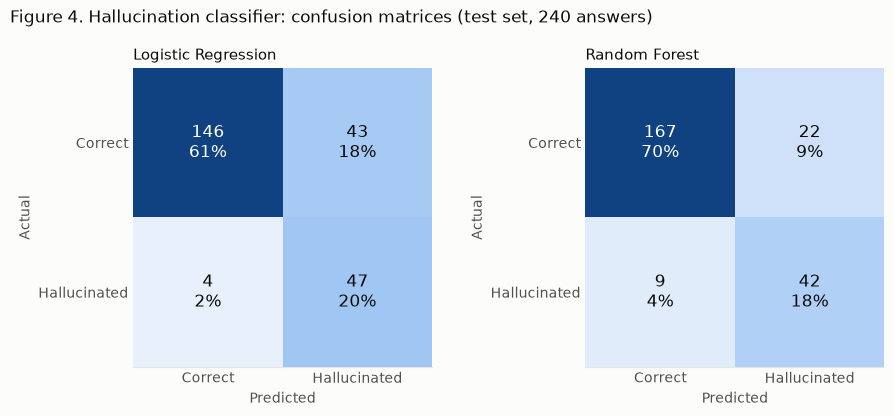

saved outputs/figures/fig4_confusion_matrix.png


In [5]:
pred = load(config.OUTPUT_DIR / "classifier_predictions.csv")
if pred is not None:
    actual = pred["hallucinated"].astype(int).values
    panels = [("Logistic Regression", "risk_logistic_regression"), ("Random Forest", "risk_random_forest")]
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.2))
    for ax, (name, col) in zip(axes, panels):
        predicted = (pred[col] >= 0.5).astype(int).values
        cm = np.array([[((actual == a) & (predicted == p)).sum() for p in (0, 1)] for a in (0, 1)])
        share = cm / cm.sum()
        ax.imshow(share, cmap=BLUES, vmin=0, vmax=share.max())
        for (i, j), k in np.ndenumerate(cm):
            ax.text(j, i, f"{k}\n{100 * share[i, j]:.0f}%", ha="center", va="center", fontsize=12,
                    color="white" if share[i, j] > 0.55 * share.max() else INK)
        ax.set_xticks([0, 1], ["Correct", "Hallucinated"])
        ax.set_yticks([0, 1], ["Correct", "Hallucinated"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        ax.set_title(name, fontsize=11)
        ax.grid(False); ax.tick_params(length=0)
    fig.suptitle(f"Figure 4. Hallucination classifier: confusion matrices (test set, {len(actual)} answers)",
                 fontsize=12, x=0.02, ha="left")
    fig.tight_layout()
    save(fig, "fig4_confusion_matrix.png")

## 6.6 Figure 5: SHAP summary

Section 4 already drew this plot (it needs SHAP and scikit-learn); here we show it and copy it under the report's figure name.

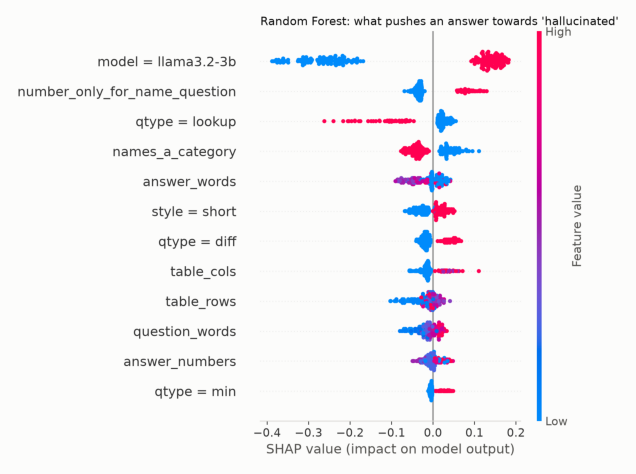

saved outputs/figures/fig5_shap_summary.png


In [6]:
src = FIG / "shap_summary_rf.png"
if src.exists():
    shutil.copy(src, FIG / "fig5_shap_summary.png")
    img = mpimg.imread(src)
    fig, ax = plt.subplots(figsize=(8, 8 * img.shape[0] / img.shape[1]))
    ax.imshow(img); ax.axis("off")
    plt.show()
    print("saved outputs/figures/fig5_shap_summary.png")
else:
    print("  (missing: outputs/figures/shap_summary_rf.png - run Section 4)")

## 6.7 Figure 6 (extension): chart images

From Section 3b (40 chart images, development results). **Confidently wrong** = a wrong answer given with no warning: every wrong answer from the vision model alone, but only wrong answers labelled *verified* once the layer is used.

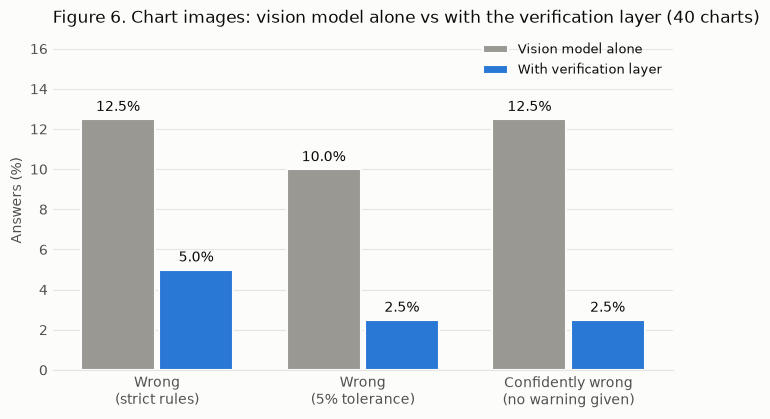

saved outputs/figures/fig6_image_pipeline.png


In [7]:
img_ba = load(TAB / "image_before_after.csv", index_col=0)
if img_ba is not None:
    measures = {"wrong_%": "Wrong\n(strict rules)", "wrong_%_(5% tolerance)": "Wrong\n(5% tolerance)",
                "confidently_wrong_%": "Confidently wrong\n(no warning given)"}
    fig, ax = plt.subplots(figsize=(8, 4.4))
    x, w = np.arange(len(measures)), 0.36
    for j, (row, colour, label) in enumerate([("vision model alone", MUTED, "Vision model alone"),
                                              ("with verification layer", "#2a78d6", "With verification layer")]):
        vals = img_ba.loc[row, list(measures)].values.astype(float)
        ax.bar(x + (j - 0.5) * (w + 0.02), vals, w, label=label, color=colour, edgecolor=SURFACE, linewidth=1.5)
        for xi, val in zip(x, vals):
            ax.text(xi + (j - 0.5) * (w + 0.02), val + 0.4, f"{val:.1f}%", ha="center", fontsize=10)
    ax.set_xticks(x, list(measures.values()))
    ax.set_ylabel("Answers (%)")
    ax.set_ylim(0, img_ba.values.max() * 1.35)
    ax.tick_params(length=0)
    ax.legend(fontsize=9, loc="upper right")
    ax.set_title("Figure 6. Chart images: vision model alone vs with the verification layer (40 charts)")
    save(fig, "fig6_image_pipeline.png")

## 6.8 Final summary table

Every headline number in one place, each with where it came from. **Report the "Note" column too**: it carries the caveats that keep the numbers honest.

In [8]:
S = []
def add(area, metric, value, note=""):
    S.append({"area": area, "metric": metric, "value": value, "note": note})

# --- Section 1: the oracle
op = load(TAB / "oracle_precision.csv", index_col=0)
if op is not None:
    add("1 Oracle", "Oracle precision vs human gold (all types)",
        f"{100 * op['correct'].sum() / op['answered'].sum():.1f}%",
        f"{op['correct'].sum()} of {op['answered'].sum()} answered; only gold-matching questions kept")
    add("1 Oracle", "Evaluation sample", "200 questions", "stratified by question type; ChartQA test split")

# --- Section 3: before / after
for _, r in fig1.iterrows():
    add("3 Verification", f"Hallucination rate BEFORE: {r['group']}", f"{r['before_%']:.1f}%",
        f"{int(r['answers'])} answers")
if audit is not None:
    add("3 Verification", "Hallucination rate AFTER (all groups)",
        f"{100 * (1 - v['hallucinated'].mean()) * miss_rate:.1f}%",
        f"verifier misses in audit: {misses}/{n_pass}; 95% upper bound "
        f"{100 * (1 - v['hallucinated'].mean()) * miss_upper:.1f}%")
fixed = v[v["hallucinated"]]
add("3 Verification", "Flagged answers fixed by re-prompting",
    f"{(fixed['final_source'] == 'reprompt').sum()} of {len(fixed)}",
    f"{(fixed['final_source'] == 'template').sum()} needed the template fallback; "
    "the model was given the correct value")

va = load(TAB / "verifier_audit.csv", index_col=0)
if va is not None:
    va = va.iloc[:, 0]
    for m in ["precision", "recall", "F1", "false_positive_rate", "false_negative_rate"]:
        add("3 Verifier audit", f"Verifier {m.replace('_', ' ')}", f"{va[m]:.3f}",
            f"human audit of {int(va['labelled_rows'])} answers (60 flagged + 60 passed)")

# --- Section 3b: images (development results)
ext = load(TAB / "image_extraction.csv", index_col=0)
if ext is not None:
    for model, r in ext.iterrows():
        add("3b Images (dev)", f"Values read correctly: {model}", f"{r['cell_accuracy_%']:.1f}%",
            "vs ChartQA's true tables; parser refined on these charts")
cc = load(TAB / "image_crosscheck.csv", index_col=0)
if cc is not None:
    cc = cc.iloc[:, 0]
    add("3b Images (dev)", "Values confirmed by both models that were right", f"{cc['confirmed_right_%']:.1f}%",
        f"{int(cc['confirmed_values'])} confirmed values; {int(cc['both_agree_but_wrong'])} shared misreads")
if img_ba is not None:
    for row in img_ba.index:
        add("3b Images (dev)", f"Wrong answers: {row}", f"{img_ba.loc[row, 'wrong_%']:.1f}%",
            f"confidently wrong {img_ba.loc[row, 'confidently_wrong_%']:.1f}%; 40 questions")

# --- Section 4: classifier (cross-validated)
cv = load(TAB / "classifier_cv.csv", index_col=0)
if cv is not None:
    for model, r in cv.iterrows():
        add("4 Classifier (5-fold CV)", f"{model}: precision / recall / F1 / ROC-AUC",
            " / ".join(str(r[c]).split(" ±")[0] for c in ["precision", "recall", "f1", "roc_auc"]),
            "no true-answer features; grouped by question (no leakage)")
circ = load(TAB / "classifier_circular_sanity.csv", index_col=0)
if circ is not None:
    add("4 Classifier", "Circular model (uses true answer) F1", f"{circ.iloc[:, 0]['F1']:.3f}",
        "sanity check only: shows why true-answer features were excluded")

summary = pd.DataFrame(S)
summary.to_csv(TAB / "final_summary.csv", index=False)
pd.set_option("display.max_colwidth", 120)
summary

,area,metric,value,note
0,1 Oracle,Oracle precision vs human gold (all types),94.5%,1034 of 1094 answered; only gold-matching questions kept
1,1 Oracle,Evaluation sample,200 questions,stratified by question type; ChartQA test split
2,3 Verification,Hallucination rate BEFORE: Llama 3.2 3B · short,59.0%,200 answers
3,3 Verification,Hallucination rate BEFORE: Llama 3.2 3B · sentence,30.5%,200 answers
4,3 Verification,Hallucination rate BEFORE: Gemini Flash-Lite · short,3.0%,200 answers
5,3 Verification,Hallucination rate BEFORE: Gemini Flash-Lite · sentence,1.5%,200 answers
6,3 Verification,Hallucination rate AFTER (all groups),0.0%,verifier misses in audit: 0/60; 95% upper bound 3.7%
7,3 Verification,Flagged answers fixed by re-prompting,165 of 188,23 needed the template fallback; the model was given the correct value
8,3 Verifier audit,Verifier precision,0.983,human audit of 120 answers (60 flagged + 60 passed)
9,3 Verifier audit,Verifier recall,1.000,human audit of 120 answers (60 flagged + 60 passed)


## ✅ Done: what to put in the report

- **Figures:** `outputs/figures/fig1_…` to `fig6_…` (PNG, 200 dpi).
- **Tables:** `outputs/tables/final_summary.csv` plus one CSV per figure.
- **Caveats to state**, all already in the summary's notes:
  1. the "after" rate comes from a 120-answer human audit, with a 95% upper bound;
  2. per-type results with small *n* are uncertain;
  3. chart type is inferred from table shape;
  4. the image results are development results (parser refined on the same 40 charts);
  5. the classifier is a risk warning, not a replacement for verification;
  6. two LLMs and 200 questions from one dataset.